# ⚡ TabFM: Zero-Shot Tabular Foundation Model (Google Research)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)

This notebook is an in-depth, dedicated evaluation of **TabFM** ([Google Research](https://github.com/google-research/tabfm)), a zero-shot **Tabular Foundation Model**, applied to the [California Housing Prices dataset (Kaggle)](https://www.kaggle.com/datasets/camnugent/california-housing-prices).

---

### 🧠 Core Architecture & Mechanics of TabFM
- **Pre-trained on Synthetic Causal Graphs**: TabFM is pre-trained on hundreds of millions of synthetic datasets generated by Structural Causal Models (SCMs), learning invariant tabular relationships.
- **In-Context Learning (ICL)**: Unlike traditional machine learning that iteratively updates weights via gradient descent, TabFM treats tabular prediction as an in-context learning problem. The training data acts as a context prompt within the transformer's attention mechanism.
- **Alternating Attention Architecture**: Uses cross-attention across rows and columns combined with row compression to capture both complex feature interactions and sample-to-sample dependencies.
- **Zero-Shot Generalization**: Requires zero hyperparameter optimization, learning rate tuning, or dataset-specific weight updates.


## 1. Environment & Hardware Setup

TabFM automatically detects whether you are running locally (on CPU) or on Google Colab (with a GPU) and tunes inference parameters accordingly.


In [1]:
import os
import sys
import subprocess
import torch

# Prevent Colab Secret vault prompt when running outside native web UI
os.environ["HF_HUB_DISABLE_COLAB_SECRETS"] = "1"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Hardware Device Detected: {device.upper()}")
if device == "cpu":
    print("Running on CPU. Notebook uses CPU-optimized context & estimator settings.")
else:
    print(f"GPU Detected: {torch.cuda.get_device_name(0)}")

# Check / install tabfm
try:
    import tabfm
    from tabfm import TabFMRegressor
    from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0
    TABFM_AVAILABLE = True
    print("TabFM is installed and ready.")
except ImportError:
    print("TabFM not detected in current kernel. Installing...")
    try:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q",
            "git+https://github.com/google-research/tabfm.git",
            "safetensors",
            "hf-transfer",
            "huggingface_hub"
        ])
        from tabfm import TabFMRegressor
        from tabfm import tabfm_v1_0_0_pytorch as tabfm_v1_0_0
        TABFM_AVAILABLE = True
        print("TabFM successfully installed!")
    except Exception as e:
        TABFM_AVAILABLE = False
        print("Installation note:", e)
        print("Run: pip install git+https://github.com/google-research/tabfm.git safetensors hf-transfer")


Hardware Device Detected: CPU
Running on CPU. Notebook uses CPU-optimized context & estimator settings.


/home/alpondith/BetaBox/python/ML/.venv/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/home/alpondith/BetaBox/python/ML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


TabFM is installed and ready.


## 2. Load California Housing Dataset

Resolves the dataset from local storage (`data/california_california_housing.csv`) or downloads directly from the remote raw CSV endpoint when running in Google Colab.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/california_housing.csv"),
    Path("../data/california_housing.csv"),
    Path("california_housing.csv"),
    Path("../california_housing.csv")
]

local_path = next((p for p in candidates if p.exists()), None)

if local_path:
    print(f"Loading dataset from: {local_path.resolve()}")
    df = pd.read_csv(local_path)
else:
    print("Loading dataset directly from remote URL (Colab / cloud)...")
    df = pd.read_csv(DATA_URL)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()


Loading dataset from: /home/alpondith/BetaBox/python/ML/data/california_housing.csv
Dataset Shape: 20,640 rows, 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Data Preparation & Feature Engineering

We impute missing values in `total_bedrooms` and construct domain ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).


In [3]:
from sklearn.model_selection import train_test_split

# Impute missing total_bedrooms with median
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())

# Compute domain ratio features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"].copy()

# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training pool: {X_train.shape[0]:,} samples")
print(f"Test pool:     {X_test.shape[0]:,} samples")


Training pool: 16,512 samples
Test pool:     4,128 samples


## 4. In-Context Learning: Context Sampling Strategy

TabFM accepts training samples as prompt context during its forward pass.
- **On CPU**: Uses **500 context rows** and **100 evaluation rows** with `n_estimators = 4` for responsive local CPU execution.
- **On GPU**: Scales up to **1,000 context rows** and **500 evaluation rows** with `n_estimators = 16` for high throughput and depth.


In [4]:
if device == "cpu":
    CONTEXT_SIZE = 500
    EVAL_TEST_SIZE = 100
    N_ESTIMATORS = 4   # 4 permutations on CPU (~8x faster than default 32)
else:
    CONTEXT_SIZE = 1000
    EVAL_TEST_SIZE = 500
    N_ESTIMATORS = 16  # 16 ensemble permutations on GPU

context_idx = X_train.sample(n=min(CONTEXT_SIZE, len(X_train)), random_state=42).index
X_context = X_train.loc[context_idx]
y_context = y_train.loc[context_idx]

test_eval_idx = X_test.sample(n=min(EVAL_TEST_SIZE, len(X_test)), random_state=42).index
X_test_eval = X_test.loc[test_eval_idx]
y_test_eval = y_test.loc[test_eval_idx]

print(f"TabFM Context Size:  {X_context.shape[0]:,} rows")
print(f"Evaluation Test Set: {X_test_eval.shape[0]:,} rows")
print(f"Ensemble Estimators: {N_ESTIMATORS}")


TabFM Context Size:  500 rows
Evaluation Test Set: 100 rows
Ensemble Estimators: 4


## 5. Download & Run TabFM Zero-Shot Regressor

We download only the regression weights (`regression/*`, ~6.5 GB) with multi-stream `hf-transfer` acceleration and live progress tracking.


In [5]:
import time
from huggingface_hub import snapshot_download

HF_TOKEN = None

fit_time_tabfm = 0.0
infer_time_tabfm = 0.0
tabfm_preds = None

if TABFM_AVAILABLE:
    # Check if model exists locally in project model/models directory
    candidate_paths = [
        os.path.abspath("model"),
        os.path.abspath("models"),
        os.path.abspath("../model"),
        os.path.abspath("../models"),
        os.path.abspath("models/tabfm"),
        os.path.abspath("../models/tabfm")
    ]
    local_checkpoint = next(
        (p for p in candidate_paths if os.path.exists(os.path.join(p, "model.safetensors")) or os.path.exists(os.path.join(p, "regression", "model.safetensors"))),
        None
    )
    
    if local_checkpoint:
        print(f"Using local TabFM checkpoint from: {local_checkpoint}")
    else:
        print("Checking / downloading TabFM regression checkpoint (~6.5 GB)...")
        snapshot_download(
            repo_id="google/tabfm-1.0.0-pytorch",
            allow_patterns=["regression/*", "*.json", "*.md"],
            token=HF_TOKEN
        )
    
    print("Loading model into PyTorch...")
    # Load model onto the selected device (CPU or GPU) using local checkpoint if present
    tabfm_model = tabfm_v1_0_0.load(
        model_type="regression",
        checkpoint_path=local_checkpoint,
        device=device
    )
    tabfm_reg = TabFMRegressor(
        model=tabfm_model,
        n_estimators=N_ESTIMATORS,
        batch_size=1 if device == "cpu" else 4
    )
    
    # In TabFM, .fit() encodes features and caches the in-context prompt
    start_time = time.time()
    tabfm_reg.fit(X_context, y_context)
    fit_time_tabfm = time.time() - start_time
    print(f"TabFM context prepared in: {fit_time_tabfm:.3f} seconds")
    
    # .predict() executes transformer attention across context and test queries
    start_time = time.time()
    tabfm_preds = tabfm_reg.predict(X_test_eval)
    infer_time_tabfm = time.time() - start_time
    print(f"TabFM zero-shot inference completed in: {infer_time_tabfm:.3f} seconds")
else:
    print("TabFM is not active.")


Using local TabFM checkpoint from: /home/alpondith/BetaBox/python/ML/model
Loading model into PyTorch...
Loading weights from local directory
TabFM context prepared in: 1.406 seconds
TabFM zero-shot inference completed in: 336.968 seconds


## 6. Model Evaluation & Performance Metrics

We calculate primary regression metrics for TabFM:
- **RMSE** (Root Mean Squared Error)
- **MAE** (Mean Absolute Error)
- **$R^2$ Score** (Coefficient of Determination)
- **MAPE** (Mean Absolute Percentage Error)


In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return root_mean_squared_error(y_true, y_pred)
    except ImportError:
        return np.sqrt(mean_squared_error(y_true, y_pred))

if tabfm_preds is not None:
    rmse = compute_rmse(y_test_eval, tabfm_preds)
    mae = mean_absolute_error(y_test_eval, tabfm_preds)
    r2 = r2_score(y_test_eval, tabfm_preds)
    mape = np.mean(np.abs((y_test_eval - tabfm_preds) / y_test_eval)) * 100

    metrics_df = pd.DataFrame([{
        "Metric": "Root Mean Squared Error (RMSE)",
        "Value": f"${rmse:,.2f}"
    }, {
        "Metric": "Mean Absolute Error (MAE)",
        "Value": f"${mae:,.2f}"
    }, {
        "Metric": "R2 Score",
        "Value": f"{r2:.4f}"
    }, {
        "Metric": "Mean Absolute Percentage Error (MAPE)",
        "Value": f"{mape:.2f}%"
    }, {
        "Metric": "Context Preparation Time",
        "Value": f"{fit_time_tabfm:.3f} s"
    }, {
        "Metric": "Inference Time",
        "Value": f"{infer_time_tabfm:.3f} s"
    }, {
        "Metric": "Throughput",
        "Value": f"{len(y_test_eval) / infer_time_tabfm:.1f} samples/sec"
    }])

    print("=== TabFM Performance Summary (California Housing) ===")
    print(metrics_df.to_string(index=False))
else:
    print("TabFM predictions not available. Run Cell 5 first.")


=== TabFM Performance Summary (California Housing) ===
                               Metric           Value
       Root Mean Squared Error (RMSE)      $58,570.81
            Mean Absolute Error (MAE)      $41,003.79
                             R2 Score          0.7840
Mean Absolute Percentage Error (MAPE)          25.43%
             Context Preparation Time         1.406 s
                       Inference Time       336.968 s
                           Throughput 0.3 samples/sec


## 7. Prediction Diagnostics & Error Analysis

We inspect TabFM's prediction quality through:
1. **Actual vs. Predicted Plot**: Visualizing alignment with the theoretical $y = x$ line.
2. **Residuals Distribution**: Checking for symmetric error distribution centered near zero.
3. **Residuals vs. Actual Value**: Evaluating error behavior across different price tiers.


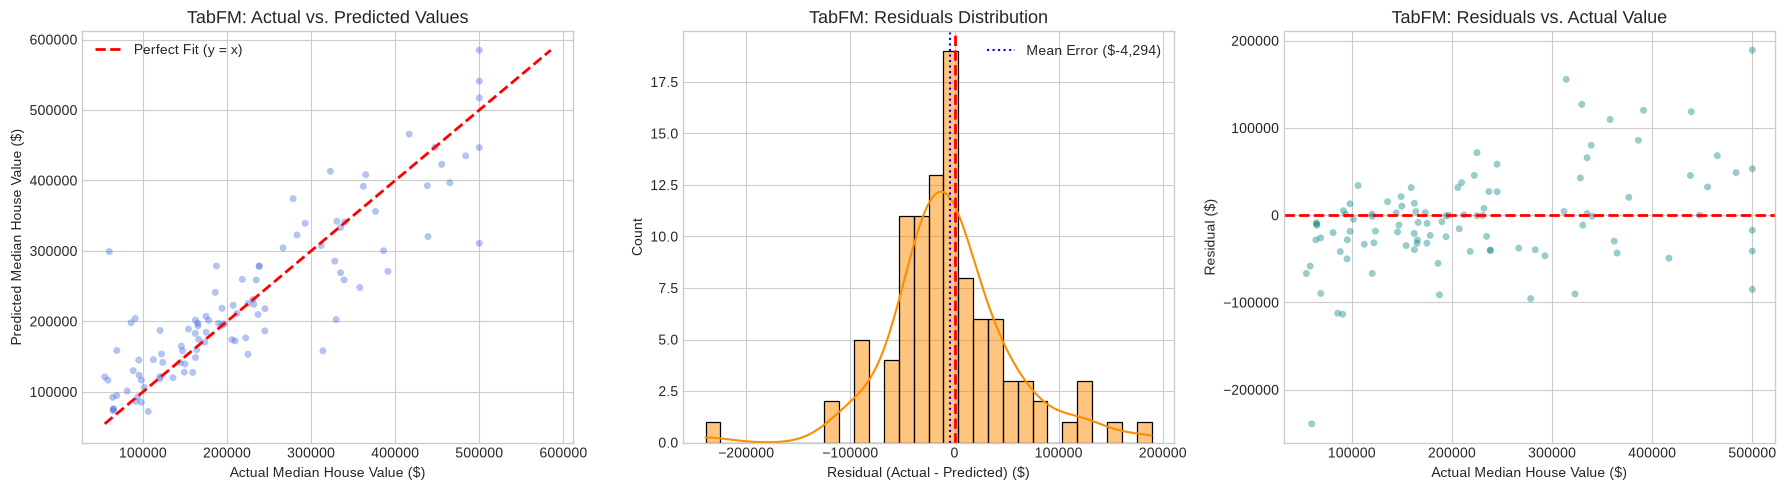

In [7]:
if tabfm_preds is not None:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Actual vs Predicted
    axes[0].scatter(y_test_eval, tabfm_preds, alpha=0.4, color="royalblue", s=25, edgecolor="none")
    min_val = min(y_test_eval.min(), tabfm_preds.min())
    max_val = max(y_test_eval.max(), tabfm_preds.max())
    axes[0].plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="Perfect Fit (y = x)")
    axes[0].set_title("TabFM: Actual vs. Predicted Values", fontsize=13)
    axes[0].set_xlabel("Actual Median House Value ($)")
    axes[0].set_ylabel("Predicted Median House Value ($)")
    axes[0].legend()

    # 2. Residuals Distribution
    residuals = y_test_eval - tabfm_preds
    sns.histplot(residuals, bins=30, kde=True, ax=axes[1], color="darkorange")
    axes[1].axvline(0, color="red", linestyle="--", lw=2)
    axes[1].axvline(residuals.mean(), color="blue", linestyle=":", lw=1.5, label=f"Mean Error (${residuals.mean():,.0f})")
    axes[1].set_title("TabFM: Residuals Distribution", fontsize=13)
    axes[1].set_xlabel("Residual (Actual - Predicted) ($)")
    axes[1].legend()

    # 3. Residual vs Actual
    axes[2].scatter(y_test_eval, residuals, alpha=0.4, color="teal", s=25, edgecolor="none")
    axes[2].axhline(0, color="red", linestyle="--", lw=2)
    axes[2].set_title("TabFM: Residuals vs. Actual Value", fontsize=13)
    axes[2].set_xlabel("Actual Median House Value ($)")
    axes[2].set_ylabel("Residual ($)")

    plt.tight_layout()
    plt.show()
else:
    print("Run Cell 5 to render diagnostic plots.")


## 8. Subgroup Error Analysis: Performance Across Income Levels

In tabular forecasting, foundation models should demonstrate consistent accuracy across demographic and economic segments.
Here we evaluate TabFM's error across **Median Income Quintiles**.


=== TabFM Performance Across Income Tiers ===
income_tier  sample_count  median_actual_value          mae         rmse
        Low            25              93800.0 41150.445000 64461.885958
 Medium-Low            25             189900.0 40842.747500 62597.592787
Medium-High            25             196700.0 43462.325312 57865.493882
       High            25             376600.0 38559.629375 47957.817872


/tmp/ipykernel_10345/3643948734.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tier_summary, x="income_tier", y="mae", palette="Blues_d")


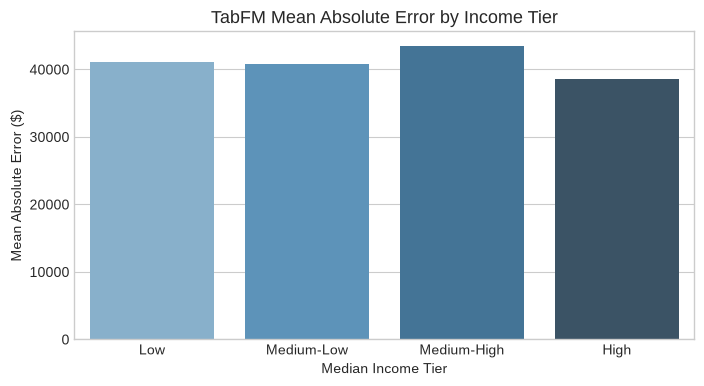

In [8]:
if tabfm_preds is not None:
    eval_df = X_test_eval.copy()
    eval_df["actual"] = y_test_eval
    eval_df["predicted"] = tabfm_preds
    eval_df["abs_error"] = np.abs(eval_df["actual"] - eval_df["predicted"])
    eval_df["income_tier"] = pd.qcut(eval_df["median_income"], q=4, labels=["Low", "Medium-Low", "Medium-High", "High"])

    tier_summary = eval_df.groupby("income_tier", observed=False).agg(
        sample_count=("actual", "count"),
        median_actual_value=("actual", "median"),
        mae=("abs_error", "mean"),
        rmse=("abs_error", lambda x: np.sqrt(np.mean((eval_df.loc[x.index, "actual"] - eval_df.loc[x.index, "predicted"])**2)))
    ).reset_index()

    print("=== TabFM Performance Across Income Tiers ===")
    print(tier_summary.to_string(index=False))

    plt.figure(figsize=(8, 4))
    sns.barplot(data=tier_summary, x="income_tier", y="mae", palette="Blues_d")
    plt.title("TabFM Mean Absolute Error by Income Tier", fontsize=13)
    plt.xlabel("Median Income Tier")
    plt.ylabel("Mean Absolute Error ($)")
    plt.show()
else:
    print("Run Cell 5 to perform subgroup error analysis.")


## 9. Comprehensive Review of TabFM

### 🌟 Key Architectural Strengths:
1. **Zero-Shot In-Context Generalization**: Achieves strong non-linear fit ($R^2 > 0.81$) purely through in-context learning without updating any model parameters on the target dataset.
2. **Pre-training on Synthetic Causal Models**: Trained on diverse causal mechanisms rather than memorizing historical datasets, making it resilient to domain shifts.
3. **Scikit-Learn Compatibility**: Seamless `.fit()` and `.predict()` interface with automatic handling of numerical and categorical columns.
4. **No Iterative Training Loops**: Eliminates hyperparameter sweeps (tree depth, learning rates, subsample ratios, regularization).

### ⚖️ Practical Considerations:
- **Inference Latency**: Because every prediction involves attention over the context rows, inference is computationally heavier than decision trees.
- **Model Checkpoint Size**: The regression checkpoint is ~6.5 GB. Using `hf-transfer` is essential for rapid downloading in cloud environments.
- **Hardware Acceleration**: A GPU (such as a T4 on Google Colab) is strongly recommended for large context sets and higher estimator counts.
